# Determinants of Depression among University Students
### An Econometric Analysis using Logit and Probit Models

This notebook runs the complete analysis behind the research report. Every table, chart and
number used in the report, the Excel workbook and the appendix is produced by the cells below.

**Data:** `data/student_sample_317.csv` — survey responses of 317 university students aged 18–24.

**Outcome:** `Depression` (Yes / No).

**Structure**
1. Setup
2. Data overview and quality checks
3. Data transformation and variable coding
4. Descriptive analysis (tables and charts)
5. Bivariate tests (chi-square, t-test, Mann–Whitney)
6. Multicollinearity check (VIF)
7. Binary logit model, odds ratios and marginal effects
8. Binary probit model and marginal effects
9. Goodness of fit and diagnostics
10. Hypothesis testing summary
11. Robustness checks
12. Export of all results (CSV, Excel, JSON)

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "student_sample_317.csv"
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
OUT = ROOT / "results" / "model_output"
for folder in (FIG, TAB, OUT):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Chart style: one blue for single series, blue/orange for No/Yes, muted text and grid.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
STATUS_COLORS = {"No": BLUE, "Yes": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False,
})

R = {}  # scalar results used in the report text


def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()


def bar_label(ax, bar, text):
    """Label inside the top of tall bars (white), above short bars (dark), so it never crosses reference lines."""
    x, h = bar.get_x() + bar.get_width() / 2, bar.get_height()
    if h >= 12:
        ax.text(x, h - 1.2, text, ha="center", va="top", fontsize=8.5, color="white", fontweight="bold")
    else:
        ax.text(x, h + 1, text, ha="center", va="bottom", fontsize=8.5, color=INK)


def save_table(df, name, index=False):
    df.to_csv(TAB / f"{name}.csv", index=index)
    return df

## 2. Data overview and quality checks

In [2]:
raw = pd.read_csv(DATA)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (317, 12)


,Student_ID,Gender,Age,Family_background,Relationship_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Living_expense,Depression
0,1,Female,21,Middle class,Single,Bachelor,7,8.00,Yes,Abnormal,High,No
1,2,Male,20,Middle class,Single,Bachelor,5,9.30,Yes,Abnormal,Mid,Yes
2,3,Male,23,Middle class,In a Relationship,Bachelor,4,9.18,Yes,Good,High,No
3,4,Male,20,Middle class,Single,Bachelor,8,7.50,Yes,Good,High,No
4,5,Male,22,Middle class,Single,Bachelor,3,8.98,Yes,Good,High,No


In [3]:
quality = pd.DataFrame({
    "Column": raw.columns,
    "Type": raw.dtypes.astype(str).values,
    "Missing": raw.isna().sum().values,
    "Unique values": raw.nunique().values,
})
print("Duplicate rows:", raw.drop(columns="Student_ID").duplicated().sum())
save_table(quality, "data_quality")

Duplicate rows: 4


,Column,Type,Missing,Unique values
0,Student_ID,int64,0,317
1,Gender,object,0,2
2,Age,int64,0,7
3,Family_background,object,0,3
4,Relationship_status,object,0,3
5,Living_style,object,0,2
6,Current_semester,int64,0,12
7,CGPA,float64,0,94
8,friend_circle,object,0,2
9,Health_condition,object,0,4


In [4]:
preview = raw.head(5).copy()
save_table(preview, "raw_data_preview")

R["n"] = int(len(raw))
R["n_depressed"] = int((raw["Depression"] == "Yes").sum())
R["n_not_depressed"] = int((raw["Depression"] == "No").sum())
R["pct_depressed"] = round(100 * R["n_depressed"] / R["n"], 1)
R["n_male"] = int((raw["Gender"] == "Male").sum())
R["n_female"] = int((raw["Gender"] == "Female").sum())
R["age_min"], R["age_max"] = int(raw["Age"].min()), int(raw["Age"].max())
R["missing_total"] = int(raw.isna().sum().sum())
R["duplicates"] = int(raw.drop(columns="Student_ID").duplicated().sum())
R

{'n': 317,
 'n_depressed': 92,
 'n_not_depressed': 225,
 'pct_depressed': 29.0,
 'n_male': 155,
 'n_female': 162,
 'age_min': 18,
 'age_max': 24,
 'missing_total': 0,
 'duplicates': 4}

## 3. Data transformation and variable coding

Text answers are converted to numbers so they can enter the regression models.

* **Binary (0/1) variables:** depression, gender (male = 1), living with family, friend circle.
* **Family background:** dummies for *Lower middle class* and *Rich class*; *Middle class* is the base group.
* **Relationship status:** *Complicated* has only 11 students and none of them is depressed, so it is
  merged with *In a relationship* — the variable becomes **Single (1) vs Not single (0)**.
* **CGPA** is on a 10.00 scale; only students with CGPA above 6.00 are in the sample.
* **Living expense** (monthly living cost excluding study costs) is recorded in three bands: *Low* (below 10,000),
  *Mid* (10,000-14,999) and *High* (15,000 and above). Dummies for *Mid* and *High*; *Low* is the base group.
* **Health condition** is kept for descriptive analysis. It is *not* used in the main model because it
  separates the outcome almost perfectly (checked in Section 4).

In [5]:
d = pd.DataFrame({"student_id": raw["Student_ID"]})
d["depression"] = (raw["Depression"] == "Yes").astype(int)
d["male"] = (raw["Gender"] == "Male").astype(int)
d["age"] = raw["Age"]
d["cgpa"] = raw["CGPA"]
d["semester"] = raw["Current_semester"]
d["cost_mid"] = (raw["Living_expense"] == "Mid").astype(int)
d["cost_high"] = (raw["Living_expense"] == "High").astype(int)
d["fam_lowermid"] = (raw["Family_background"] == "Lower Middle class").astype(int)
d["fam_rich"] = (raw["Family_background"] == "Rich class").astype(int)
d["single"] = (raw["Relationship_status"] == "Single").astype(int)
d["live_family"] = (raw["Living_style"] == "Family").astype(int)
d["friend_circle"] = (raw["friend_circle"] == "Yes").astype(int)
d["health_poor"] = raw["Health_condition"].isin(["Abnormal", "Critical"]).astype(int)
d["health_level"] = raw["Health_condition"].map({"Good": 1, "Normal": 2, "Abnormal": 3, "Critical": 4})
d.head()

,student_id,depression,male,age,cgpa,semester,cost_mid,cost_high,fam_lowermid,fam_rich,single,live_family,friend_circle,health_poor,health_level
0,1,0,0,21,8.00,7,0,1,0,0,1,0,1,1,3
1,2,1,1,20,9.30,5,1,0,0,0,1,0,1,1,3
2,3,0,1,23,9.18,4,0,1,0,0,0,0,1,0,1
3,4,0,1,20,7.50,8,0,1,0,0,1,0,1,0,1
4,5,0,1,22,8.98,3,0,1,0,0,1,0,1,0,1


In [6]:
LABELS = {
    "depression": "Depression",
    "male": "Male",
    "age": "Age (years)",
    "cgpa": "CGPA",
    "semester": "Current semester",
    "cost_mid": "Mid living expense",
    "cost_high": "High living expense",
    "fam_lowermid": "Lower-middle class",
    "fam_rich": "Rich class",
    "single": "Single",
    "live_family": "Lives with family",
    "friend_circle": "Has friend circle",
    "health_poor": "Poor health",
    "health_level": "Health level (1-4)",
}

dictionary = pd.DataFrame([
    ["depression", "Depression", "Whether the student reports depression. 1 = Yes, 0 = No.", "Binary (dependent variable)"],
    ["male", "Gender", "Gender of the student. 1 = Male, 0 = Female.", "Binary"],
    ["age", "Age", "Age of the student in years (18-24).", "Numerical (discrete)"],
    ["cgpa", "CGPA", "Cumulative grade point average on a 10.00 scale (sample restricted to CGPA above 6.00).", "Numerical (continuous)"],
    ["semester", "Current semester", "Semester the student is currently in.", "Numerical (discrete)"],
    ["cost_mid", "Living expense", "1 = Mid monthly living cost, 10,000-14,999 excluding study costs (base group: Low, below 10,000).", "Binary (dummy)"],
    ["cost_high", "Living expense", "1 = High monthly living cost, 15,000 or more excluding study costs (base group: Low, below 10,000).", "Binary (dummy)"],
    ["fam_lowermid", "Family background", "1 = Lower-middle class family (base group: middle class).", "Binary (dummy)"],
    ["fam_rich", "Family background", "1 = Rich class family (base group: middle class).", "Binary (dummy)"],
    ["single", "Relationship status", "1 = Single, 0 = In a relationship or complicated.", "Binary"],
    ["live_family", "Living style", "1 = Lives with family, 0 = Lives as a bachelor (hostel/mess/shared).", "Binary"],
    ["friend_circle", "Friend circle", "1 = Has a friend circle, 0 = Does not.", "Binary"],
    ["health_poor", "Health condition", "1 = Abnormal or critical health, 0 = Good or normal (robustness model only).", "Binary"],
    ["health_level", "Health condition", "1 = Good, 2 = Normal, 3 = Abnormal, 4 = Critical (descriptive only).", "Ordinal"],
], columns=["Variable", "Survey question", "Description and coding", "Data type"])
save_table(dictionary, "variable_dictionary")
d.to_csv(TAB / "coded_data.csv", index=False)
dictionary

,Variable,Survey question,Description and coding,Data type
0,depression,Depression,Whether the student reports depression. 1 = Ye...,Binary (dependent variable)
1,male,Gender,"Gender of the student. 1 = Male, 0 = Female.",Binary
2,age,Age,Age of the student in years (18-24).,Numerical (discrete)
3,cgpa,CGPA,Cumulative grade point average on a 10.00 scal...,Numerical (continuous)
4,semester,Current semester,Semester the student is currently in.,Numerical (discrete)
5,cost_mid,Living expense,"1 = Mid monthly living cost, 10,000-14,999 exc...",Binary (dummy)
6,cost_high,Living expense,"1 = High monthly living cost, 15,000 or more e...",Binary (dummy)
7,fam_lowermid,Family background,1 = Lower-middle class family (base group: mid...,Binary (dummy)
8,fam_rich,Family background,1 = Rich class family (base group: middle class).,Binary (dummy)
9,single,Relationship status,"1 = Single, 0 = In a relationship or complicated.",Binary


## 4. Descriptive analysis
### 4.1 Summary statistics (equivalent to Stata `summarize`)

In [7]:
NUMERIC = ["depression", "male", "age", "cgpa", "semester", "cost_mid", "cost_high", "fam_lowermid", "fam_rich",
           "single", "live_family", "friend_circle", "health_poor"]
summary = pd.DataFrame({
    "Variable": [LABELS[v] for v in NUMERIC],
    "Obs": [int(d[v].count()) for v in NUMERIC],
    "Mean": [d[v].mean() for v in NUMERIC],
    "Std. dev.": [d[v].std() for v in NUMERIC],
    "Min": [d[v].min() for v in NUMERIC],
    "Max": [d[v].max() for v in NUMERIC],
}).round(3)
save_table(summary, "summary_statistics")
summary

,Variable,Obs,Mean,Std. dev.,Min,Max
0,Depression,317,0.290,0.455,0.00,1.0
1,Male,317,0.489,0.501,0.00,1.0
2,Age (years),317,21.615,1.453,18.00,24.0
3,CGPA,317,8.753,0.862,6.25,10.0
4,Current semester,317,5.142,2.201,0.00,11.0
5,Mid living expense,317,0.287,0.453,0.00,1.0
6,High living expense,317,0.366,0.482,0.00,1.0
7,Lower-middle class,317,0.202,0.402,0.00,1.0
8,Rich class,317,0.161,0.368,0.00,1.0
9,Single,317,0.603,0.490,0.00,1.0


In [8]:
by_status = d.groupby("depression")[["age", "cgpa", "semester"]].agg(["mean", "std"]).round(3)
by_status.index = ["Not depressed", "Depressed"]
by_status

age          cgpa        semester       
                 mean    std   mean    std     mean    std
Not depressed  21.636  1.439  8.765  0.842    5.196  2.308
Depressed      21.565  1.492  8.726  0.914    5.011  1.919

### 4.2 Depression in the sample (equivalent to Stata `tabulate depression`)

In [9]:
tab_dep = raw["Depression"].value_counts().reindex(["No", "Yes"]).rename_axis("Depression").reset_index(name="Freq.")
tab_dep["Percent"] = (100 * tab_dep["Freq."] / tab_dep["Freq."].sum()).round(2)
tab_dep["Cum."] = tab_dep["Percent"].cumsum().round(2)
save_table(tab_dep, "tabulate_depression")
tab_dep

,Depression,Freq.,Percent,Cum.
0,No,225,70.98,70.98
1,Yes,92,29.02,100.00


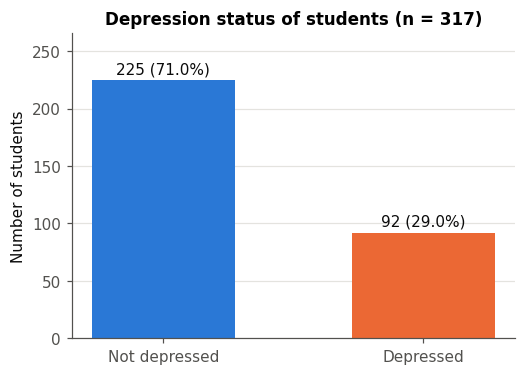

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
bars = ax.bar(["Not depressed", "Depressed"], tab_dep["Freq."], color=[BLUE, ORANGE], width=0.55)
for bar, n, pct in zip(bars, tab_dep["Freq."], tab_dep["Percent"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3, f"{n} ({pct:.1f}%)",
            ha="center", va="bottom", color=INK)
ax.set_ylabel("Number of students")
ax.set_title(f"Depression status of students (n = {len(raw)})")
ax.set_ylim(0, tab_dep["Freq."].max() * 1.18)
ax.grid(axis="x", visible=False)
save_fig(fig, "fig01_depression_distribution")

### 4.3 Depression rate by student characteristics

In [11]:
GROUP_VARS = {
    "Gender": ["Female", "Male"],
    "Family_background": ["Lower Middle class", "Middle class", "Rich class"],
    "Relationship_status": ["Single", "In a Relationship", "Complicated"],
    "Living_style": ["Bachelor", "Family"],
    "Living_expense": ["Low", "Mid", "High"],
    "friend_circle": ["No", "Yes"],
    "Health_condition": ["Good", "Normal", "Abnormal", "Critical"],
}
NICE = {"Gender": "Gender", "Family_background": "Family background", "Relationship_status": "Relationship status",
        "Living_style": "Living style", "Living_expense": "Living expense", "friend_circle": "Friend circle",
        "Health_condition": "Health condition"}

rows = []
for var, levels in GROUP_VARS.items():
    for level in levels:
        grp = raw[raw[var] == level]
        rows.append([NICE[var], level, len(grp), int((grp["Depression"] == "Yes").sum()),
                     round(100 * (grp["Depression"] == "Yes").mean(), 1)])
rates = pd.DataFrame(rows, columns=["Characteristic", "Group", "Students", "Depressed", "Depression rate (%)"])
save_table(rates, "depression_rates_by_group")
rates

,Characteristic,Group,Students,Depressed,Depression rate (%)
0,Gender,Female,162,45,27.8
1,Gender,Male,155,47,30.3
2,Family background,Lower Middle class,64,13,20.3
3,Family background,Middle class,202,71,35.1
4,Family background,Rich class,51,8,15.7
5,Relationship status,Single,191,82,42.9
6,Relationship status,In a Relationship,115,10,8.7
7,Relationship status,Complicated,11,0,0.0
8,Living style,Bachelor,188,64,34.0
9,Living style,Family,129,28,21.7


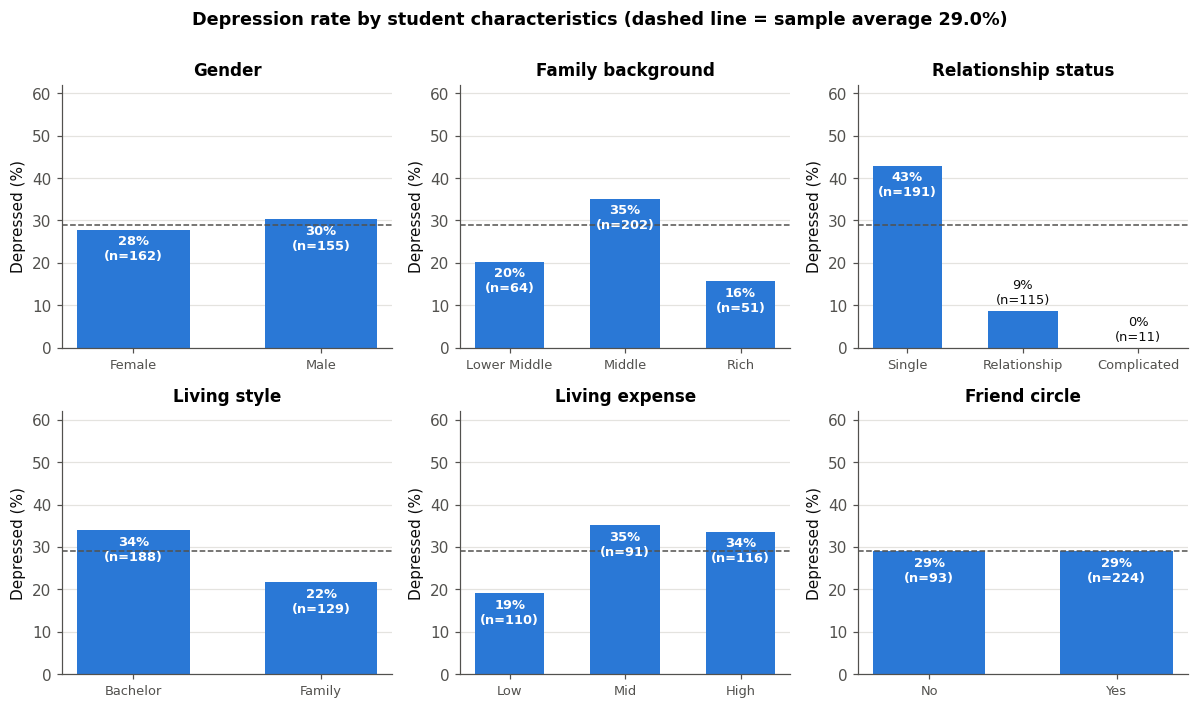

In [12]:
overall = 100 * d["depression"].mean()
panels = ["Gender", "Family_background", "Relationship_status", "Living_style", "Living_expense", "friend_circle"]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
for ax, var in zip(axes.ravel(), panels):
    sub = rates[rates["Characteristic"] == NICE[var]]
    bars = ax.bar(sub["Group"].str.replace(" class", "").str.replace("In a ", ""), sub["Depression rate (%)"],
                  color=BLUE, width=0.6)
    for bar, rate, n in zip(bars, sub["Depression rate (%)"], sub["Students"]):
        bar_label(ax, bar, f"{rate:.0f}%\n(n={n})")
    ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_title(NICE[var])
    ax.set_ylim(0, 62)
    ax.set_ylabel("Depressed (%)")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8.5)
fig.suptitle(f"Depression rate by student characteristics (dashed line = sample average {overall:.1f}%)",
             fontsize=11.5, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "fig02_rates_by_group")

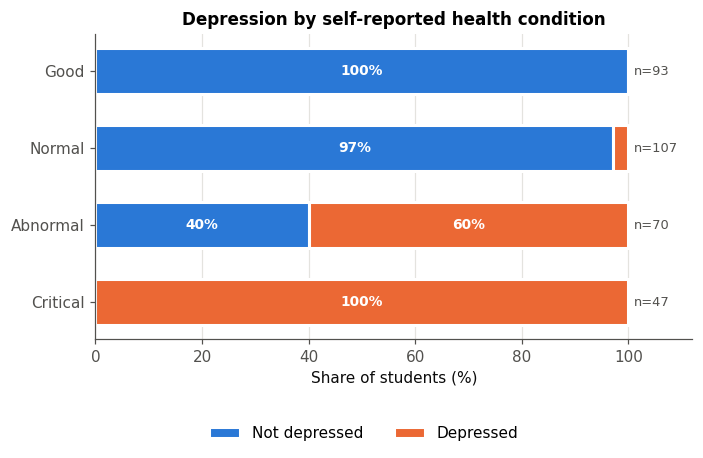

Depression,No,Yes
Health_condition,,
Good,93,0
Normal,104,3
Abnormal,28,42
Critical,0,47


In [13]:
hc = pd.crosstab(raw["Health_condition"], raw["Depression"]).reindex(["Good", "Normal", "Abnormal", "Critical"])
hc_pct = hc.div(hc.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(7, 3.6))
left = np.zeros(len(hc_pct))
for status in ["No", "Yes"]:
    ax.barh(hc_pct.index, hc_pct[status], left=left, color=STATUS_COLORS[status], height=0.6,
            edgecolor="white", linewidth=2, label="Not depressed" if status == "No" else "Depressed")
    for i, (val, start) in enumerate(zip(hc_pct[status], left)):
        if val >= 6:
            ax.text(start + val / 2, i, f"{val:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += hc_pct[status].values
for i, total in enumerate(hc.sum(axis=1)):
    ax.text(101, i, f"n={total}", va="center", fontsize=8.5, color=MUTED)
ax.set_xlim(0, 112)
ax.invert_yaxis()
ax.set_xlabel("Share of students (%)")
ax.set_title("Depression by self-reported health condition")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.38), ncol=2)
ax.grid(axis="y", visible=False)
save_fig(fig, "fig03_health_condition")

R["health_critical_rate"] = float(hc_pct.loc["Critical", "Yes"].round(1))
R["health_good_rate"] = float(hc_pct.loc["Good", "Yes"].round(1))
R["health_normal_rate"] = float(hc_pct.loc["Normal", "Yes"].round(1))
R["health_abnormal_rate"] = float(hc_pct.loc["Abnormal", "Yes"].round(1))
hc

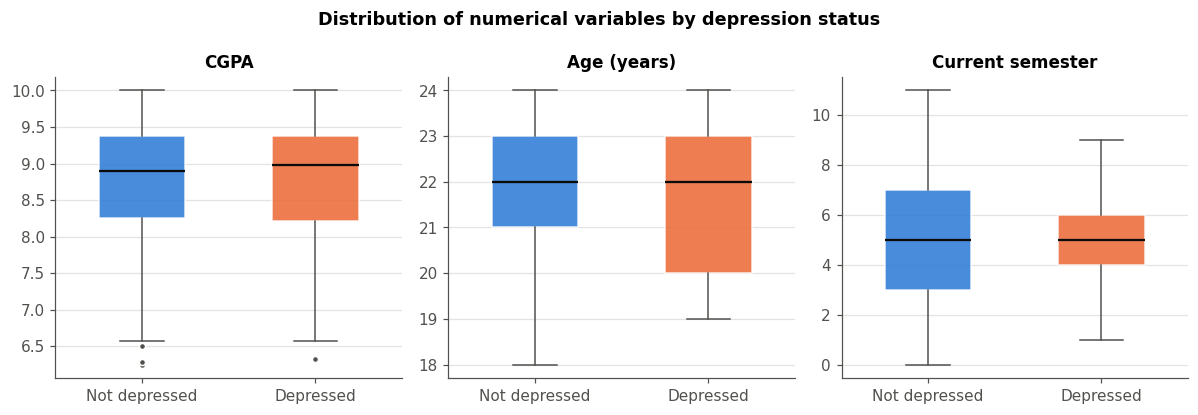

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (var, title) in zip(axes, [("cgpa", "CGPA"), ("age", "Age (years)"), ("semester", "Current semester")]):
    groups = [d.loc[d["depression"] == 0, var], d.loc[d["depression"] == 1, var]]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.5, medianprops={"color": INK, "linewidth": 1.5},
                    whiskerprops={"color": MUTED}, capprops={"color": MUTED},
                    flierprops={"marker": "o", "markersize": 4, "markerfacecolor": MUTED, "markeredgecolor": "white"})
    for patch, color in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(color)
        patch.set_edgecolor("white")
        patch.set_alpha(0.85)
    ax.set_xticks([1, 2], ["Not depressed", "Depressed"])
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribution of numerical variables by depression status", fontsize=11.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig04_numeric_by_depression")

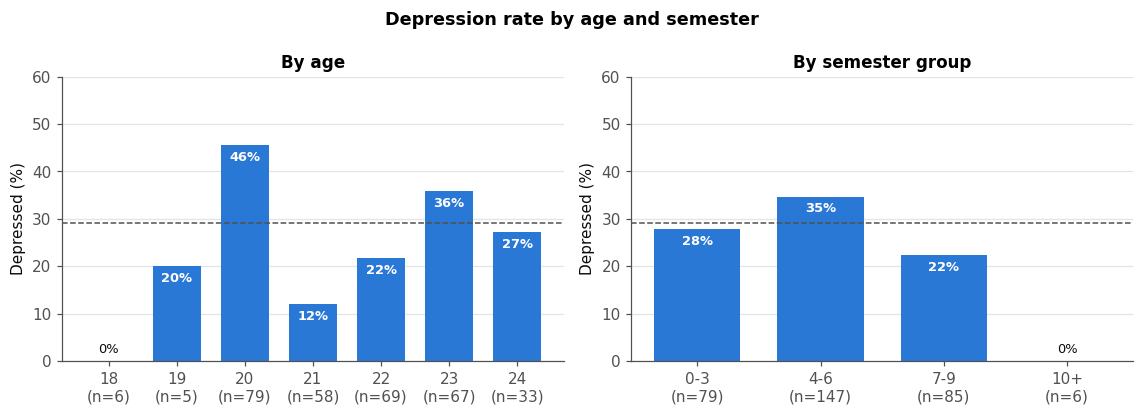

In [15]:
age_rates = d.groupby("age")["depression"].agg(["size", "mean"]).reset_index()
d["semester_group"] = pd.cut(d["semester"], bins=[-1, 3, 6, 9, 20], labels=["0-3", "4-6", "7-9", "10+"])
sem_rates = d.groupby("semester_group", observed=True)["depression"].agg(["size", "mean"]).reset_index()
save_table(age_rates.rename(columns={"size": "Students", "mean": "Depression rate"}), "depression_rate_by_age")
save_table(sem_rates.rename(columns={"size": "Students", "mean": "Depression rate"}), "depression_rate_by_semester")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for ax, tbl, key, title in [(axes[0], age_rates, "age", "By age"), (axes[1], sem_rates, "semester_group", "By semester group")]:
    tick_labels = [f"{k}\n(n={n})" for k, n in zip(tbl[key].astype(str), tbl["size"])]
    bars = ax.bar(tick_labels, 100 * tbl["mean"], color=BLUE, width=0.7)
    for bar, rate in zip(bars, 100 * tbl["mean"]):
        bar_label(ax, bar, f"{rate:.0f}%")
    ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_ylim(0, 60)
    ax.set_ylabel("Depressed (%)")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
fig.suptitle("Depression rate by age and semester", fontsize=11.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig05_rate_by_age_semester")

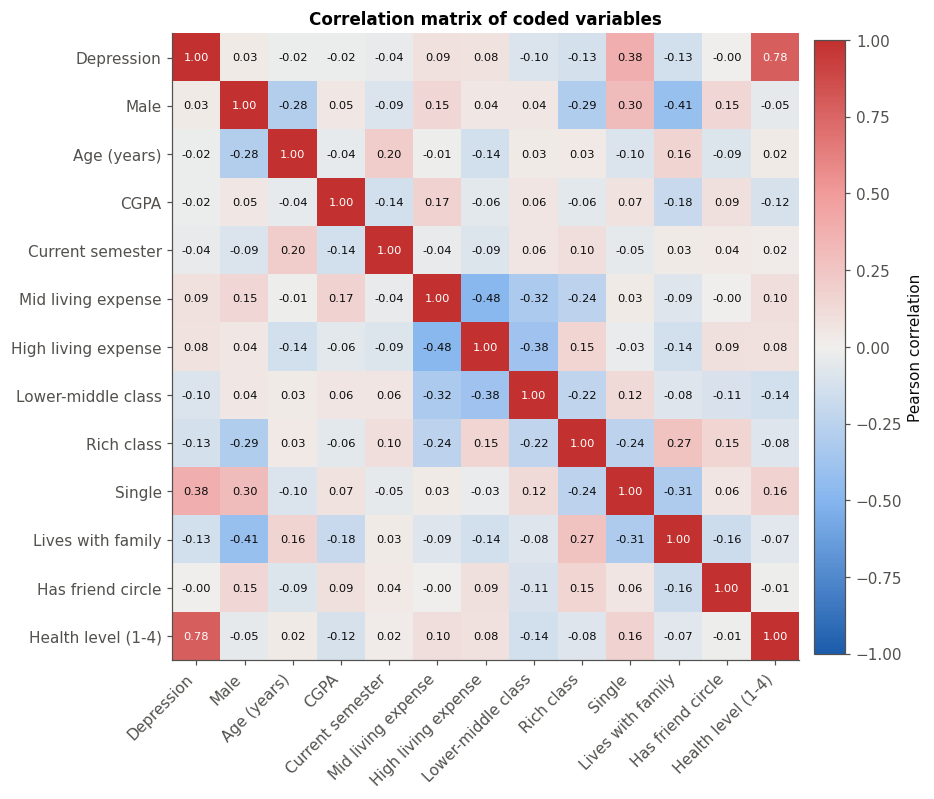

In [16]:
from matplotlib.colors import LinearSegmentedColormap

CORR_VARS = ["depression", "male", "age", "cgpa", "semester", "cost_mid", "cost_high", "fam_lowermid", "fam_rich",
             "single", "live_family", "friend_circle", "health_level"]
corr = d[CORR_VARS].corr()
save_table(corr.round(3).rename(index=LABELS, columns=LABELS), "correlation_matrix", index=True)

diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f19c9b", "#c2302f"])
fig, ax = plt.subplots(figsize=(9, 7.4))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR_VARS)), [LABELS[v] for v in CORR_VARS], rotation=45, ha="right")
ax.set_yticks(range(len(CORR_VARS)), [LABELS[v] for v in CORR_VARS])
for i in range(len(CORR_VARS)):
    for j in range(len(CORR_VARS)):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(val) > 0.55 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="Pearson correlation")
ax.set_title("Correlation matrix of coded variables")
save_fig(fig, "fig06_correlation_matrix")

## 5. Bivariate tests
### 5.1 Chi-square tests of independence (categorical variables vs depression)

In [17]:
def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


chi_rows = []
for var in GROUP_VARS:
    table = pd.crosstab(raw[var], raw["Depression"])
    chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
    row = [NICE[var], round(chi2, 3), dof, p, round(cramers_v(table), 3), round(expected.min(), 2)]
    row.append(stats.fisher_exact(table.values)[1] if table.shape == (2, 2) else np.nan)
    chi_rows.append(row)
chi_tests = pd.DataFrame(chi_rows, columns=["Variable", "Chi-square", "df", "p-value", "Cramer's V",
                                            "Min expected count", "Fisher exact p (2x2)"])
save_table(chi_tests, "chi_square_tests")
chi_tests

,Variable,Chi-square,df,p-value,Cramer's V,Min expected count,Fisher exact p (2x2)
0,Gender,0.249,1,6.177620e-01,0.028,44.98,0.623099
1,Family background,10.440,2,5.406105e-03,0.181,14.80,NaN
2,Relationship status,45.504,2,1.315189e-10,0.379,3.19,NaN
3,Living style,5.653,1,1.742741e-02,0.134,37.44,0.023078
4,Living expense,8.125,2,1.721008e-02,0.160,26.41,NaN
5,Friend circle,0.000,1,9.979477e-01,0.000,26.99,1.000000
6,Health condition,221.288,3,1.057306e-47,0.836,13.64,NaN


### 5.2 Difference in means (numerical variables): Welch t-test and Mann–Whitney U test

In [18]:
t_rows = []
for var in ["cgpa", "age", "semester"]:
    a, b = d.loc[d["depression"] == 0, var], d.loc[d["depression"] == 1, var]
    t, p_t = stats.ttest_ind(b, a, equal_var=False)
    u, p_u = stats.mannwhitneyu(b, a, alternative="two-sided")
    t_rows.append([LABELS[var], a.mean(), b.mean(), b.mean() - a.mean(), t, p_t, u, p_u])
t_tests = pd.DataFrame(t_rows, columns=["Variable", "Mean (not depressed)", "Mean (depressed)", "Difference",
                                        "Welch t", "t-test p-value", "Mann-Whitney U", "Mann-Whitney p-value"]).round(4)
save_table(t_tests, "t_tests")
t_tests

,Variable,Mean (not depressed),Mean (depressed),Difference,Welch t,t-test p-value,Mann-Whitney U,Mann-Whitney p-value
0,CGPA,8.7647,8.7261,-0.0386,-0.3489,0.7277,10366.0,0.9833
1,Age (years),21.6356,21.5652,-0.0703,-0.3848,0.7009,9881.5,0.5184
2,Current semester,5.1956,5.0109,-0.1847,-0.7318,0.4651,10066.0,0.6985


## 6. Multicollinearity check (Variance Inflation Factor)

In [19]:
MAIN = ["male", "age", "cgpa", "semester", "cost_mid", "cost_high", "fam_lowermid", "fam_rich",
        "single", "live_family", "friend_circle"]
y = d["depression"]
X = sm.add_constant(d[MAIN].astype(float))
vif = pd.DataFrame({
    "Variable": [LABELS[v] for v in MAIN],
    "VIF": [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
}).round(3)
vif["Tolerance (1/VIF)"] = (1 / vif["VIF"]).round(3)
save_table(vif, "vif")
R["vif_max"] = float(vif["VIF"].max())
vif

,Variable,VIF,Tolerance (1/VIF)
0,Male,1.427,0.701
1,Age (years),1.154,0.867
2,CGPA,1.120,0.893
3,Current semester,1.089,0.918
4,Mid living expense,2.896,0.345
5,High living expense,2.769,0.361
6,Lower-middle class,2.500,0.400
7,Rich class,1.411,0.709
8,Single,1.190,0.840
9,Lives with family,1.457,0.686


## 7. Binary logit model

$$\Pr(\text{Depression}_i = 1) = \Lambda(\beta_0 + \beta_1\,\text{Male}_i + \beta_2\,\text{Age}_i + \beta_3\,\text{CGPA}_i
+ \beta_4\,\text{Semester}_i + \beta_5\,\text{MidExpense}_i + \beta_6\,\text{HighExpense}_i + \beta_7\,\text{LowerMid}_i + \beta_8\,\text{Rich}_i
+ \beta_9\,\text{Single}_i + \beta_{10}\,\text{LiveFamily}_i + \beta_{11}\,\text{FriendCircle}_i)$$

where $\Lambda(z) = e^z / (1 + e^z)$. Stata equivalent: `logit depression male age cgpa semester i.cost_mid i.cost_high i.fam_lowermid ...`

In [20]:
logit = sm.Logit(y, X).fit(disp=0)
print(logit.summary())
(OUT / "logit_summary.txt").write_text(logit.summary().as_text())


def coef_table(res, labels=LABELS):
    ci = res.conf_int()
    table = pd.DataFrame({
        "Variable": ["Constant" if v == "const" else labels[v] for v in res.params.index],
        "Coefficient": res.params.values,
        "Std. err.": res.bse.values,
        "z": res.tvalues.values,
        "P>|z|": res.pvalues.values,
        "95% CI lower": ci[0].values,
        "95% CI upper": ci[1].values,
    })
    return table


def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


logit_table = coef_table(logit)
logit_table["Sig."] = logit_table["P>|z|"].apply(stars)
save_table(logit_table.round(4), "logit_coefficients")
logit_table.round(4)

                           Logit Regression Results                           
Dep. Variable:             depression   No. Observations:                  317
Model:                          Logit   Df Residuals:                      305
Method:                           MLE   Df Model:                           11
Date:                Wed, 07 Oct 2026   Pseudo R-squ.:                  0.1886
Time:                        22:07:04   Log-Likelihood:                -154.94
converged:                       True   LL-Null:                       -190.94
Covariance Type:            nonrobust   LLR p-value:                 5.058e-11
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -1.0825      2.655     -0.408      0.683      -6.286       4.121
male             -0.8725      0.345     -2.531      0.011      -1.548      -0.197
age               0.0238      0.102     

,Variable,Coefficient,Std. err.,z,P>|z|,95% CI lower,95% CI upper,Sig.
0,Constant,-1.0825,2.6549,-0.4077,0.6835,-6.2860,4.1211,
1,Male,-0.8725,0.3447,-2.5307,0.0114,-1.5481,-0.1968,**
2,Age (years),0.0238,0.1017,0.2344,0.8146,-0.1754,0.2231,
3,CGPA,-0.2465,0.1745,-1.4125,0.1578,-0.5886,0.0956,
4,Current semester,-0.0200,0.0703,-0.2850,0.7756,-0.1578,0.1177,
5,Mid living expense,1.2083,0.5884,2.0535,0.0400,0.0550,2.3616,**
6,High living expense,1.2214,0.5758,2.1214,0.0339,0.0929,2.3500,**
7,Lower-middle class,0.0204,0.6015,0.0338,0.9730,-1.1587,1.1994,
8,Rich class,-0.8066,0.5128,-1.5731,0.1157,-1.8117,0.1984,
9,Single,2.4750,0.3995,6.1950,0.0000,1.6920,3.2581,***


### 7.1 Odds ratios (Stata: `logit ..., or`)

In [21]:
or_table = pd.DataFrame({
    "Variable": logit_table["Variable"],
    "Odds ratio": np.exp(logit.params.values),
    "95% CI lower": np.exp(logit.conf_int()[0].values),
    "95% CI upper": np.exp(logit.conf_int()[1].values),
    "P>|z|": logit.pvalues.values,
}).round(4)
or_table["Sig."] = or_table["P>|z|"].apply(stars)
save_table(or_table, "logit_odds_ratios")
or_table

,Variable,Odds ratio,95% CI lower,95% CI upper,P>|z|,Sig.
0,Constant,0.3388,0.0019,61.6252,0.6835,
1,Male,0.4179,0.2126,0.8214,0.0114,**
2,Age (years),1.0241,0.8391,1.2500,0.8146,
3,CGPA,0.7815,0.5551,1.1003,0.1578,
4,Current semester,0.9802,0.8540,1.1249,0.7756,
5,Mid living expense,3.3479,1.0566,10.6080,0.0400,**
6,High living expense,3.3921,1.0974,10.4852,0.0339,**
7,Lower-middle class,1.0206,0.3139,3.3180,0.9730,
8,Rich class,0.4464,0.1634,1.2194,0.1157,
9,Single,11.8823,5.4303,26.0003,0.0000,***


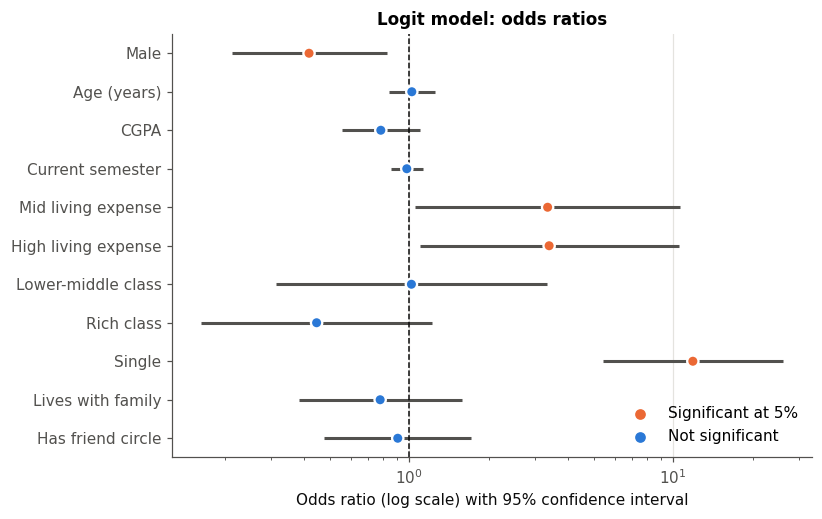

In [22]:
plot_or = or_table[or_table["Variable"] != "Constant"].iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
sig = plot_or["P>|z|"] < 0.05
ax.hlines(range(len(plot_or)), plot_or["95% CI lower"], plot_or["95% CI upper"], color=MUTED, linewidth=2)
ax.scatter(plot_or["Odds ratio"], range(len(plot_or)), s=55, zorder=3,
           color=[ORANGE if s else BLUE for s in sig], edgecolor="white", linewidth=1.5)
ax.axvline(1, color=INK, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(range(len(plot_or)), plot_or["Variable"])
ax.set_xlabel("Odds ratio (log scale) with 95% confidence interval")
ax.set_title("Logit model: odds ratios")
ax.scatter([], [], color=ORANGE, label="Significant at 5%")
ax.scatter([], [], color=BLUE, label="Not significant")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig07_logit_odds_ratios")

### 7.2 Marginal effects after logit
**Average marginal effects (AME)** — Stata: `margins, dydx(*)`. For 0/1 variables the effect is the discrete change
from 0 to 1. **Marginal effects at the means (MEM)** — Stata: `margins, dydx(*) atmeans` (older `mfx`).

In [23]:
def margeff_table(res, at):
    frame = res.get_margeff(at=at, dummy=True).summary_frame()
    frame.index = [LABELS[v] for v in frame.index]
    frame = frame.reset_index().rename(columns={"index": "Variable", "dy/dx": "dy/dx", "Std. Err.": "Std. err.",
                                                "Pr(>|z|)": "P>|z|", "Conf. Int. Low": "95% CI lower",
                                                "Cont. Int. Hi.": "95% CI upper"})
    frame["Sig."] = frame["P>|z|"].apply(stars)
    return frame.round(4)


logit_ame = margeff_table(logit, "overall")
logit_mem = margeff_table(logit, "mean")
save_table(logit_ame, "logit_marginal_effects_ame")
save_table(logit_mem, "logit_marginal_effects_mem")
R["logit_pred_at_means"] = float(logit.predict(X.mean().to_frame().T)[0])
print("Predicted probability of depression at the means:", round(R["logit_pred_at_means"], 4))
logit_ame

Predicted probability of depression at the means: 0.2196


,Variable,dy/dx,Std. err.,z,P>|z|,95% CI lower,95% CI upper,Sig.
0,Male,-0.1403,0.0523,-2.6851,0.0073,-0.2427,-0.0379,***
1,Age (years),0.0039,0.0166,0.2345,0.8146,-0.0287,0.0365,
2,CGPA,-0.0403,0.0282,-1.4290,0.1530,-0.0956,0.0150,
3,Current semester,-0.0033,0.0115,-0.2852,0.7755,-0.0258,0.0192,
4,Mid living expense,0.2014,0.0941,2.1416,0.0322,0.0171,0.3858,**
5,High living expense,0.1998,0.0882,2.2646,0.0235,0.0269,0.3728,**
6,Lower-middle class,0.0033,0.0985,0.0338,0.9730,-0.1898,0.1964,
7,Rich class,-0.1202,0.0672,-1.7881,0.0738,-0.2519,0.0115,*
8,Single,0.3664,0.0425,8.6233,0.0000,0.2831,0.4496,***
9,Lives with family,-0.0410,0.0584,-0.7026,0.4823,-0.1554,0.0734,


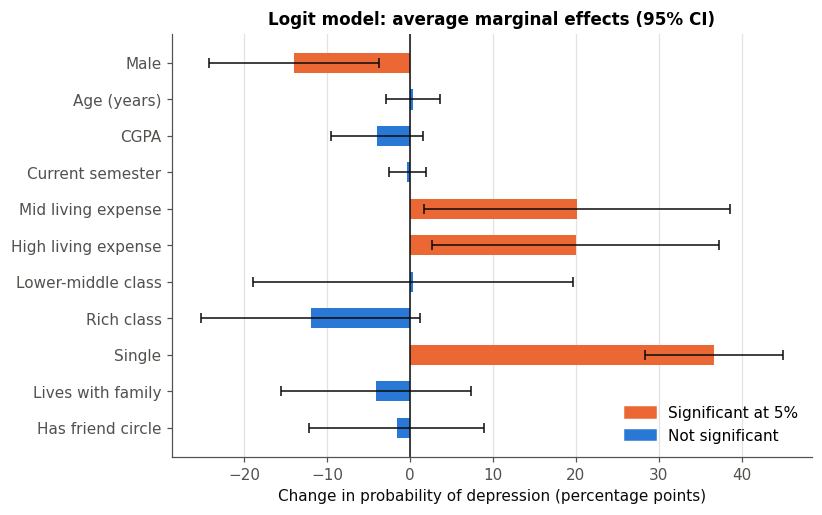

In [24]:
plot_me = logit_ame.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
sig = plot_me["P>|z|"] < 0.05
ax.barh(plot_me["Variable"], 100 * plot_me["dy/dx"], color=[ORANGE if s else BLUE for s in sig], height=0.55)
ax.errorbar(100 * plot_me["dy/dx"], range(len(plot_me)),
            xerr=[100 * (plot_me["dy/dx"] - plot_me["95% CI lower"]), 100 * (plot_me["95% CI upper"] - plot_me["dy/dx"])],
            fmt="none", ecolor=INK, elinewidth=1, capsize=3)
ax.axvline(0, color=INK, linewidth=1)
ax.set_xlabel("Change in probability of depression (percentage points)")
ax.set_title("Logit model: average marginal effects (95% CI)")
ax.legend(handles=[Patch(color=ORANGE, label="Significant at 5%"), Patch(color=BLUE, label="Not significant")],
          loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig08_logit_marginal_effects")

## 8. Binary probit model
$$\Pr(\text{Depression}_i = 1) = \Phi(\mathbf{x}_i'\boldsymbol\beta)$$ where $\Phi$ is the standard normal CDF.
Stata equivalent: `probit depression ...` followed by `margins, dydx(*)`.

In [25]:
probit = sm.Probit(y, X).fit(disp=0)
print(probit.summary())
(OUT / "probit_summary.txt").write_text(probit.summary().as_text())
probit_table = coef_table(probit)
probit_table["Sig."] = probit_table["P>|z|"].apply(stars)
save_table(probit_table.round(4), "probit_coefficients")
probit_table.round(4)

                          Probit Regression Results                           
Dep. Variable:             depression   No. Observations:                  317
Model:                         Probit   Df Residuals:                      305
Method:                           MLE   Df Model:                           11
Date:                Wed, 07 Oct 2026   Pseudo R-squ.:                  0.1901
Time:                        22:07:05   Log-Likelihood:                -154.64
converged:                       True   LL-Null:                       -190.94
Covariance Type:            nonrobust   LLR p-value:                 3.885e-11
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.7478      1.603     -0.466      0.641      -3.890       2.394
male             -0.5496      0.203     -2.702      0.007      -0.948      -0.151
age               0.0177      0.061     

,Variable,Coefficient,Std. err.,z,P>|z|,95% CI lower,95% CI upper,Sig.
0,Constant,-0.7478,1.6031,-0.4665,0.6409,-3.8898,2.3942,
1,Male,-0.5496,0.2034,-2.7020,0.0069,-0.9483,-0.1509,***
2,Age (years),0.0177,0.0605,0.2931,0.7695,-0.1009,0.1363,
3,CGPA,-0.1410,0.1025,-1.3761,0.1688,-0.3418,0.0598,
4,Current semester,-0.0093,0.0405,-0.2301,0.8180,-0.0887,0.0701,
5,Mid living expense,0.7374,0.3536,2.0856,0.0370,0.0444,1.4303,**
6,High living expense,0.7417,0.3416,2.1713,0.0299,0.0722,1.4112,**
7,Lower-middle class,0.0291,0.3598,0.0810,0.9354,-0.6760,0.7343,
8,Rich class,-0.3668,0.2833,-1.2946,0.1955,-0.9221,0.1885,
9,Single,1.4319,0.2166,6.6114,0.0000,1.0074,1.8564,***


In [26]:
probit_ame = margeff_table(probit, "overall")
probit_mem = margeff_table(probit, "mean")
save_table(probit_ame, "probit_marginal_effects_ame")
save_table(probit_mem, "probit_marginal_effects_mem")
R["probit_pred_at_means"] = float(probit.predict(X.mean().to_frame().T)[0])
probit_ame

,Variable,dy/dx,Std. err.,z,P>|z|,95% CI lower,95% CI upper,Sig.
0,Male,-0.1481,0.0517,-2.8665,0.0041,-0.2493,-0.0468,***
1,Age (years),0.0049,0.0166,0.2933,0.7693,-0.0277,0.0374,
2,CGPA,-0.0387,0.0279,-1.3874,0.1653,-0.0934,0.0160,
3,Current semester,-0.0026,0.0111,-0.2302,0.8180,-0.0244,0.0192,
4,Mid living expense,0.2077,0.0963,2.1568,0.0310,0.0190,0.3964,**
5,High living expense,0.2051,0.0893,2.2964,0.0217,0.0300,0.3802,**
6,Lower-middle class,0.0080,0.0992,0.0809,0.9355,-0.1863,0.2024,
7,Rich class,-0.0946,0.0677,-1.3971,0.1624,-0.2273,0.0381,
8,Single,0.3689,0.0430,8.5863,0.0000,0.2847,0.4531,***
9,Lives with family,-0.0493,0.0567,-0.8697,0.3845,-0.1605,0.0618,


## 9. Goodness of fit and diagnostics

In [27]:
def hosmer_lemeshow(y_true, p_hat, groups=10):
    frame = pd.DataFrame({"y": y_true, "p": p_hat})
    frame["g"] = pd.qcut(frame["p"], groups, duplicates="drop")
    g = frame.groupby("g", observed=True).agg(obs=("y", "sum"), exp=("p", "sum"), n=("y", "size"))
    hl = (((g["obs"] - g["exp"]) ** 2) / (g["exp"] * (1 - g["exp"] / g["n"]))).sum()
    dof = len(g) - 2
    return hl, dof, 1 - stats.chi2.cdf(hl, dof)


def classification(y_true, p_hat, cutoff=0.5):
    pred = (p_hat >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"Cutoff": cutoff, "True positives": tp, "False positives": fp, "False negatives": fn,
            "True negatives": tn, "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
            "Correctly classified": (tp + tn) / len(y_true)}


fit_rows, class_rows = [], []
for name, res in [("Logit", logit), ("Probit", probit)]:
    p_hat = res.predict(X)
    hl, hl_df, hl_p = hosmer_lemeshow(y, p_hat)
    fit_rows.append({"Model": name, "Observations": int(res.nobs), "Log likelihood": res.llf,
                     "Log likelihood (null)": res.llnull, "LR chi2": res.llr, "LR df": int(res.df_model),
                     "Prob > chi2": res.llr_pvalue, "Pseudo R2 (McFadden)": res.prsquared,
                     "AIC": res.aic, "BIC": res.bic, "AUC (ROC)": roc_auc_score(y, p_hat),
                     "Hosmer-Lemeshow chi2": hl, "HL df": hl_df, "HL p-value": hl_p})
    for cut in (0.5, y.mean()):
        class_rows.append({"Model": name, **classification(y, p_hat, cut)})
fit_stats = pd.DataFrame(fit_rows).round(4)
class_table = pd.DataFrame(class_rows).round(4)
save_table(fit_stats, "model_fit_statistics")
save_table(class_table, "classification_tables")
fit_stats.T

,0,1
Model,Logit,Probit
Observations,317,317
Log likelihood,-154.9392,-154.6391
Log likelihood (null),-190.9447,-190.9447
LR chi2,72.011,72.6112
LR df,11,11
Prob > chi2,0.0,0.0
Pseudo R2 (McFadden),0.1886,0.1901
AIC,333.8784,333.2783
BIC,378.9853,378.3851


In [28]:
class_table

,Model,Cutoff,True positives,False positives,False negatives,True negatives,Sensitivity,Specificity,Correctly classified
0,Logit,0.5000,23,27,69,198,0.2500,0.8800,0.6972
1,Logit,0.2902,78,74,14,151,0.8478,0.6711,0.7224
2,Probit,0.5000,24,29,68,196,0.2609,0.8711,0.6940
3,Probit,0.2902,78,78,14,147,0.8478,0.6533,0.7098


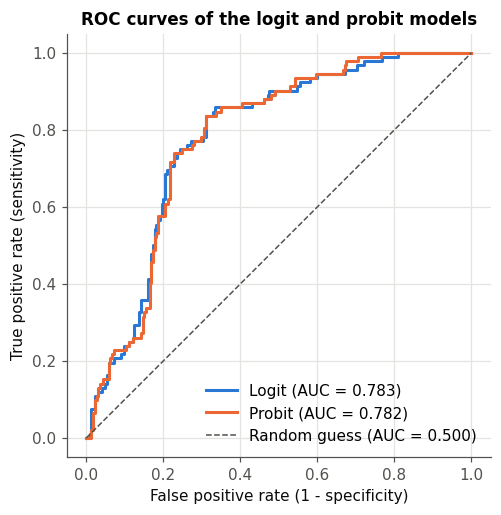

In [29]:
fig, ax = plt.subplots(figsize=(5.6, 5))
roc_points = []
for name, res, color in [("Logit", logit, BLUE), ("Probit", probit, ORANGE)]:
    fpr, tpr, _ = roc_curve(y, res.predict(X))
    roc_points += [{"Model": name, "False positive rate": a, "True positive rate": b} for a, b in zip(fpr, tpr)]
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y, res.predict(X)):.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random guess (AUC = 0.500)")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curves of the logit and probit models")
ax.legend(loc="lower right")
ax.set_aspect("equal")
save_table(pd.DataFrame(roc_points).round(4), "roc_curve_points")
save_fig(fig, "fig09_roc_curves")

### 9.1 Predicted probability profiles
Predicted probability of depression across CGPA, for single and not-single students, with all other variables at their means.

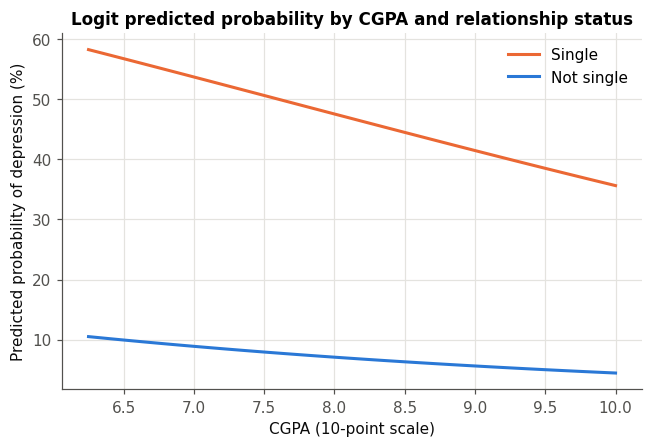

In [30]:
grid = np.linspace(d["cgpa"].min(), d["cgpa"].max(), 60)
fig, ax = plt.subplots(figsize=(6.8, 4.2))
profile_rows = []
for single, color, label in [(1, ORANGE, "Single"), (0, BLUE, "Not single")]:
    base = X.mean().to_frame().T.loc[np.repeat(0, len(grid))].reset_index(drop=True)
    base["cgpa"], base["single"] = grid, single
    p = logit.predict(base)
    ax.plot(grid, 100 * p, color=color, linewidth=2, label=label)
    profile_rows += [{"CGPA": g, "Single": single, "Predicted probability": v} for g, v in zip(grid, p)]
ax.set_xlabel("CGPA (10-point scale)")
ax.set_ylabel("Predicted probability of depression (%)")
ax.set_title("Logit predicted probability by CGPA and relationship status")
ax.legend()
save_table(pd.DataFrame(profile_rows).round(4), "predicted_probability_profiles")
save_fig(fig, "fig10_predicted_probability_cgpa")

## 10. Hypothesis testing summary
Decision rule: a hypothesis is **supported** when the logit coefficient has the expected sign and p < 0.05.

In [31]:
HYPOTHESES = [
    ("H1", "Students with higher CGPA are less likely to be depressed (academic stress).", "cgpa", "-"),
    ("H2", "Students with a friend circle are less likely to be depressed (social support).", "friend_circle", "-"),
    ("H3", "Single students are more likely to be depressed than students in a relationship.", "single", "+"),
    ("H4a", "Students from lower-middle class families are more likely to be depressed than middle class.", "fam_lowermid", "+"),
    ("H4b", "Students from rich families are less likely to be depressed than middle class.", "fam_rich", "-"),
    ("H5", "Students with high living expenses are more likely to be depressed than those with low expenses (financial pressure).", "cost_high", "+"),
    ("H6", "Students living with family are less likely to be depressed than those living as bachelors.", "live_family", "-"),
    ("H7", "Female students are more likely to be depressed than male students.", "male", "-"),
]
h_rows = []
for code, text, var, sign in HYPOTHESES:
    b, p = logit.params[var], logit.pvalues[var]
    ame = logit_ame.set_index("Variable").loc[LABELS[var], "dy/dx"]
    right_sign = (b < 0) if sign == "-" else (b > 0)
    if p < 0.05 and right_sign:
        verdict = "Supported"
    elif p < 0.05:
        verdict = "Rejected (significant, opposite sign)"
    elif p < 0.10 and right_sign:
        verdict = "Weakly supported (10% level)"
    else:
        verdict = "Not supported (not significant)"
    h_rows.append([code, text, LABELS[var], sign, round(b, 4), round(ame, 4), round(p, 4), verdict])
hyp = pd.DataFrame(h_rows, columns=["Hypothesis", "Statement", "Variable", "Expected sign", "Logit coefficient",
                                    "AME", "P>|z|", "Result"])
save_table(hyp, "hypothesis_tests")
hyp

,Hypothesis,Statement,Variable,Expected sign,Logit coefficient,AME,P>|z|,Result
0,H1,Students with higher CGPA are less likely to b...,CGPA,-,-0.2465,-0.0403,0.1578,Not supported (not significant)
1,H2,Students with a friend circle are less likely ...,Has friend circle,-,-0.0988,-0.0162,0.7624,Not supported (not significant)
2,H3,Single students are more likely to be depresse...,Single,+,2.4750,0.3664,0.0000,Supported
3,H4a,Students from lower-middle class families are ...,Lower-middle class,+,0.0204,0.0033,0.9730,Not supported (not significant)
4,H4b,Students from rich families are less likely to...,Rich class,-,-0.8066,-0.1202,0.1157,Not supported (not significant)
5,H5,Students with high living expenses are more li...,High living expense,+,1.2214,0.1998,0.0339,Supported
6,H6,Students living with family are less likely to...,Lives with family,-,-0.2524,-0.0410,0.4868,Not supported (not significant)
7,H7,Female students are more likely to be depresse...,Male,-,-0.8725,-0.1403,0.0114,Supported


## 11. Robustness checks
* **(1) Logit** — main model.
* **(2) Logit, robust SE** — heteroskedasticity-robust (HC1) standard errors (Stata: `vce(robust)`).
* **(3) Probit** — different link function.
* **(4) Linear probability model (LPM)** — OLS with robust SE (Stata: `regress ..., vce(robust)`).
* **(5) Logit + poor health** — adds the health indicator to show how strongly it dominates.
* **(6)/(7) Male and female students separately — linear probability model with robust SE.**
  A logit cannot be used here: among male students, none of the non-single students is depressed, so
  `single` predicts the outcome perfectly in the male subsample (quasi-complete separation) and its logit
  coefficient goes to infinity. The LPM is not affected by separation, so it is used for both subsamples.

In [32]:
logit_robust = sm.Logit(y, X).fit(disp=0, cov_type="HC1")
lpm = sm.OLS(y, X).fit(cov_type="HC1")
X_health = sm.add_constant(d[MAIN + ["health_poor"]].astype(float))
logit_health = sm.Logit(y, X_health).fit(disp=0, maxiter=200)
(OUT / "lpm_summary.txt").write_text(lpm.summary().as_text())
(OUT / "logit_robust_summary.txt").write_text(logit_robust.summary().as_text())
(OUT / "logit_health_summary.txt").write_text(logit_health.summary().as_text())

separation = pd.crosstab([raw["Gender"], raw["Relationship_status"] == "Single"], raw["Depression"])
separation.index = separation.index.set_names(["Gender", "Single"])
save_table(separation.reset_index(), "separation_check_gender_single")
print(separation)
R["male_not_single_n"] = int(separation.loc[("Male", False)].sum())
R["male_not_single_depressed"] = int(separation.loc[("Male", False), "Yes"])

sub_models = {}
for label, flag in [("Male students", 1), ("Female students", 0)]:
    sub = d[d["male"] == flag]
    Xs = sm.add_constant(sub[[v for v in MAIN if v != "male"]].astype(float))
    sub_models[label] = sm.OLS(sub["depression"], Xs).fit(cov_type="HC1")
    (OUT / f"lpm_{label.split()[0].lower()}_summary.txt").write_text(sub_models[label].summary().as_text())

models = {"(1) Logit": logit, "(2) Logit robust SE": logit_robust, "(3) Probit": probit, "(4) LPM robust SE": lpm,
          "(5) Logit + poor health": logit_health, "(6) LPM male": sub_models["Male students"],
          "(7) LPM female": sub_models["Female students"]}


def cell(res, var):
    if var not in res.params.index:
        return ""
    return f"{res.params[var]:.3f}{stars(res.pvalues[var])}\n({res.bse[var]:.3f})"


ALL_VARS = ["const"] + MAIN + ["health_poor"]
robust = pd.DataFrame({name: [cell(res, v) for v in ALL_VARS] for name, res in models.items()},
                      index=["Constant" if v == "const" else LABELS[v] for v in ALL_VARS])
footer = pd.DataFrame({name: [str(int(res.nobs)),
                              f"{res.prsquared:.3f}" if hasattr(res, "prsquared") else f"{res.rsquared:.3f}"]
                       for name, res in models.items()}, index=["Observations", "Pseudo R2 / R2"])
robust = pd.concat([robust, footer]).reset_index().rename(columns={"index": "Variable"})
save_table(robust, "robustness_models")
robust

Depression     No  Yes
Gender Single         
Female False   78   10
       True    39   35
Male   False   38    0
       True    70   47


,Variable,(1) Logit,(2) Logit robust SE,(3) Probit,(4) LPM robust SE,(5) Logit + poor health,(6) LPM male,(7) LPM female
0,Constant,-1.082\n(2.655),-1.082\n(2.552),-0.748\n(1.603),0.365\n(0.477),-2.025\n(7.074),0.218\n(0.625),0.177\n(0.762)
1,Male,-0.872**\n(0.345),-0.872***\n(0.329),-0.550***\n(0.203),-0.135**\n(0.054),-1.935**\n(0.956),,
2,Age (years),0.024\n(0.102),0.024\n(0.099),0.018\n(0.061),0.002\n(0.017),-0.212\n(0.241),-0.029\n(0.023),0.028\n(0.029)
3,CGPA,-0.247\n(0.175),-0.247\n(0.179),-0.141\n(0.102),-0.034\n(0.029),-0.024\n(0.420),0.029\n(0.047),-0.080**\n(0.040)
4,Current semester,-0.020\n(0.070),-0.020\n(0.074),-0.009\n(0.041),-0.003\n(0.011),-0.091\n(0.161),0.002\n(0.017),-0.012\n(0.015)
5,Mid living expense,1.208**\n(0.588),1.208**\n(0.505),0.737**\n(0.354),0.135*\n(0.082),-1.010\n(1.207),0.278***\n(0.094),0.167\n(0.113)
6,High living expense,1.221**\n(0.576),1.221**\n(0.503),0.742**\n(0.342),0.129*\n(0.072),-0.721\n(1.068),0.298***\n(0.096),0.145\n(0.094)
7,Lower-middle class,0.020\n(0.602),0.020\n(0.546),0.029\n(0.360),-0.065\n(0.087),-1.311\n(1.319),0.004\n(0.103),0.056\n(0.122)
8,Rich class,-0.807\n(0.513),-0.807\n(0.568),-0.367\n(0.283),-0.082\n(0.077),0.932\n(0.848),-0.445***\n(0.097),-0.002\n(0.104)
9,Single,2.475***\n(0.400),2.475***\n(0.390),1.432***\n(0.217),0.376***\n(0.046),5.981***\n(1.144),0.394***\n(0.059),0.342***\n(0.071)


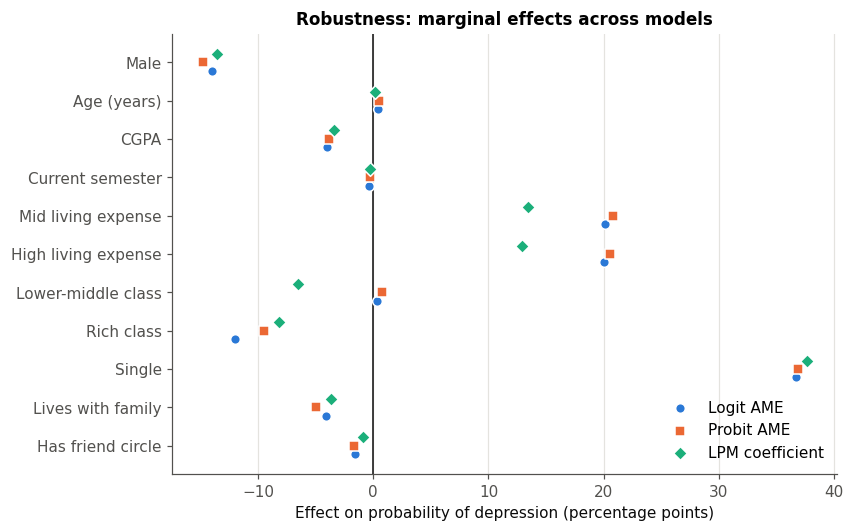

,Variable,Logit AME,Logit AME p,Probit AME,Probit AME p,LPM coefficient,LPM p (robust)
0,Male,-0.1403,0.0073,-0.1481,0.0041,-0.1355,0.0127
1,Age (years),0.0039,0.8146,0.0049,0.7693,0.0018,0.9189
2,CGPA,-0.0403,0.1530,-0.0387,0.1653,-0.0341,0.2408
3,Current semester,-0.0033,0.7755,-0.0026,0.8180,-0.0026,0.8133
4,Mid living expense,0.2014,0.0322,0.2077,0.0310,0.1347,0.0995
5,High living expense,0.1998,0.0235,0.2051,0.0217,0.1292,0.0738
6,Lower-middle class,0.0033,0.9730,0.0080,0.9355,-0.0654,0.4507
7,Rich class,-0.1202,0.0738,-0.0946,0.1624,-0.0816,0.2865
8,Single,0.3664,0.0000,0.3689,0.0000,0.3764,0.0000
9,Lives with family,-0.0410,0.4823,-0.0493,0.3845,-0.0363,0.5103


In [33]:
compare = pd.DataFrame({
    "Variable": logit_ame["Variable"],
    "Logit AME": logit_ame["dy/dx"].values,
    "Logit AME p": logit_ame["P>|z|"].values,
    "Probit AME": probit_ame["dy/dx"].values,
    "Probit AME p": probit_ame["P>|z|"].values,
    "LPM coefficient": lpm.params[MAIN].values,
    "LPM p (robust)": lpm.pvalues[MAIN].values,
}).round(4)
save_table(compare, "marginal_effects_comparison")

fig, ax = plt.subplots(figsize=(7.8, 5.2))
ypos = np.arange(len(compare))[::-1]
for offset, col, color, marker, label in [(-0.22, "Logit AME", BLUE, "o", "Logit AME"),
                                          (0, "Probit AME", ORANGE, "s", "Probit AME"),
                                          (0.22, "LPM coefficient", "#1baf7a", "D", "LPM coefficient")]:
    ax.scatter(100 * compare[col], ypos + offset, color=color, marker=marker, s=40, label=label,
               edgecolor="white", linewidth=1, zorder=3)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(ypos, compare["Variable"])
ax.set_xlabel("Effect on probability of depression (percentage points)")
ax.set_title("Robustness: marginal effects across models")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig11_robustness_comparison")
compare

In [34]:
sub_ame = []  # LPM coefficients are marginal effects directly
for label, res in sub_models.items():
    for var in res.params.index.drop("const"):
        sub_ame.append({"Sample": label, "Variable": LABELS[var], "dy/dx": res.params[var], "P>|z|": res.pvalues[var],
                        "Observations": int(res.nobs), "Depressed": int(res.model.endog.sum())})
sub_ame = pd.DataFrame(sub_ame).round(4)
save_table(sub_ame, "subsample_marginal_effects")
sub_ame.pivot(index="Variable", columns="Sample", values=["dy/dx", "P>|z|"])

dy/dx                         P>|z|              
Sample              Female students Male students Female students Male students
Variable                                                                       
Age (years)                  0.0277       -0.0291          0.3404        0.2031
CGPA                        -0.0800        0.0290          0.0444        0.5368
Current semester            -0.0117        0.0020          0.4311        0.9067
Has friend circle            0.0166       -0.0716          0.8171        0.3670
High living expense          0.1446        0.2983          0.1246        0.0018
Lives with family           -0.0245        0.0106          0.7433        0.8864
Lower-middle class           0.0565        0.0042          0.6429        0.9679
Mid living expense           0.1670        0.2783          0.1405        0.0029
Rich class                  -0.0015       -0.4449          0.9884        0.0000
Single                       0.3423        0.3938          0.0000        0.0000

In [35]:
lr_health = 2 * (logit_health.llf - logit.llf)
R["lr_health_chi2"] = float(lr_health)
R["lr_health_p"] = float(1 - stats.chi2.cdf(lr_health, 1))
R["health_model_pseudo_r2"] = float(logit_health.prsquared)
R["health_model_auc"] = float(roc_auc_score(y, logit_health.predict(X_health)))
print(f"Adding poor health: LR chi2 = {lr_health:.2f}, p = {R['lr_health_p']:.3g}, "
      f"pseudo R2 {logit.prsquared:.3f} -> {logit_health.prsquared:.3f}")

Adding poor health: LR chi2 = 231.25, p = 0, pseudo R2 0.189 -> 0.794


## 12. Export all results

In [36]:
R.update({
    "logit_ll": float(logit.llf), "logit_lr_chi2": float(logit.llr), "logit_lr_df": int(logit.df_model),
    "logit_lr_p": float(logit.llr_pvalue), "logit_pseudo_r2": float(logit.prsquared),
    "logit_aic": float(logit.aic), "logit_bic": float(logit.bic),
    "probit_ll": float(probit.llf), "probit_lr_chi2": float(probit.llr), "probit_lr_p": float(probit.llr_pvalue),
    "probit_pseudo_r2": float(probit.prsquared), "probit_aic": float(probit.aic), "probit_bic": float(probit.bic),
    "logit_auc": float(fit_stats.loc[0, "AUC (ROC)"]), "probit_auc": float(fit_stats.loc[1, "AUC (ROC)"]),
    "logit_hl_chi2": float(fit_stats.loc[0, "Hosmer-Lemeshow chi2"]), "logit_hl_p": float(fit_stats.loc[0, "HL p-value"]),
    "logit_correct_05": float(class_table.loc[0, "Correctly classified"]),
    "logit_sens_05": float(class_table.loc[0, "Sensitivity"]), "logit_spec_05": float(class_table.loc[0, "Specificity"]),
    "lpm_r2": float(lpm.rsquared),
})
(ROOT / "results" / "results.json").write_text(json.dumps(R, indent=2))
R

{'n': 317,
 'n_depressed': 92,
 'n_not_depressed': 225,
 'pct_depressed': 29.0,
 'n_male': 155,
 'n_female': 162,
 'age_min': 18,
 'age_max': 24,
 'missing_total': 0,
 'duplicates': 4,
 'health_critical_rate': 100.0,
 'health_good_rate': 0.0,
 'health_normal_rate': 2.8,
 'health_abnormal_rate': 60.0,
 'vif_max': 2.896,
 'logit_pred_at_means': 0.21960032443669367,
 'probit_pred_at_means': 0.2296015108078992,
 'male_not_single_n': 38,
 'male_not_single_depressed': 0,
 'lr_health_chi2': 231.25097415992025,
 'lr_health_p': 0.0,
 'health_model_pseudo_r2': 0.7941093562927772,
 'health_model_auc': 0.9864251207729469,
 'logit_ll': -154.93921895628546,
 'logit_lr_chi2': 72.01100755664231,
 'logit_lr_df': 11,
 'logit_lr_p': 5.057750317517488e-11,
 'logit_pseudo_r2': 0.18856506355698066,
 'logit_aic': 333.8784379125709,
 'logit_bic': 378.98525919909827,
 'probit_ll': -154.639138795097,
 'probit_lr_chi2': 72.6111678980024,
 'probit_lr_p': 3.8848606912832344e-11,
 'probit_pseudo_r2': 0.190136618741

In [37]:
from openpyxl import load_workbook
from openpyxl.drawing.image import Image as XLImage
from openpyxl.styles import Alignment, Font, PatternFill

XLSX = ROOT / "results" / "Student_Depression_Analysis_Results.xlsx"
about = pd.DataFrame({"Item": ["Title", "Data", "Outcome", "Main models", "Software", "Sheets"],
                      "Details": ["Determinants of Depression among University Students",
                                  f"{R['n']} university students aged {R['age_min']}-{R['age_max']}",
                                  f"Depression (Yes = 1): {R['n_depressed']} students ({R['pct_depressed']}%)",
                                  "Binary logit and probit with marginal effects; LPM and subsample robustness checks",
                                  "Python (pandas, statsmodels, scipy); equivalent Stata code in stata/",
                                  "One sheet per analysis step, in the order of the report"]})
sheets = [
    ("About", about), ("Raw data", raw), ("Coded data", d.drop(columns="semester_group")),
    ("Variable dictionary", dictionary), ("Data quality", quality), ("Summary statistics", summary),
    ("Tabulate depression", tab_dep), ("Rates by group", rates), ("Rate by age", age_rates),
    ("Rate by semester", sem_rates), ("Correlation", corr.round(3).rename(index=LABELS, columns=LABELS).reset_index()),
    ("Chi-square tests", chi_tests), ("t-tests", t_tests), ("VIF", vif),
    ("Logit", logit_table.round(4)), ("Odds ratios", or_table), ("Logit AME", logit_ame), ("Logit MEM", logit_mem),
    ("Probit", probit_table.round(4)), ("Probit AME", probit_ame), ("Probit MEM", probit_mem),
    ("Model fit", fit_stats), ("Classification", class_table), ("Hypotheses", hyp),
    ("Robustness models", robust), ("ME comparison", compare), ("Subsample AME", sub_ame),
]
with pd.ExcelWriter(XLSX, engine="openpyxl") as writer:
    for name, frame in sheets:
        frame.to_excel(writer, sheet_name=name, index=False)

wb = load_workbook(XLSX)
header_fill = PatternFill("solid", fgColor="DCE8F7")
for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    for c in ws[1]:
        c.font = Font(bold=True)
        c.fill = header_fill
        c.alignment = Alignment(wrap_text=True, vertical="center")
    for col in ws.columns:
        width = max(len(str(c.value)) if c.value is not None else 0 for c in col[:200])
        ws.column_dimensions[col[0].column_letter].width = min(max(10, width + 2), 60)
    for row in ws.iter_rows(min_row=2):
        for c in row:
            if isinstance(c.value, float):
                c.number_format = "0.0000"
            if isinstance(c.value, str) and "\n" in c.value:
                c.alignment = Alignment(wrap_text=True)
figs = wb.create_sheet("Figures")
figs["A1"] = "Charts produced by the analysis notebook"
figs["A1"].font = Font(bold=True, size=13)
row = 3
for png in sorted(FIG.glob("*.png")):
    figs.cell(row=row, column=1, value=png.stem).font = Font(bold=True)
    img = XLImage(str(png))
    scale = 720 / img.width
    img.width, img.height = img.width * scale, img.height * scale
    figs.add_image(img, f"A{row + 1}")
    row += int(img.height / 20) + 4
wb.save(XLSX)
print("Saved", XLSX.name, "with", len(wb.sheetnames), "sheets")

Saved Student_Depression_Analysis_Results.xlsx with 28 sheets
